# Exploratory Data Analysis: Titanic Survival

**Author:** Aidi Sara · **Tools:** Python, pandas, seaborn

An EDA of the 891 training passengers on the RMS Titanic. The analysis looks at
who survived and why, using demographics, ticket class, family structure, and fare.
**Headline finding:** gender and class jointly explain most of the variation —
1st/2nd-class women survived at ~95%, while 3rd-class men survived at only ~14%.
Age, family size, and cabin presence add secondary signal.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")

URL  = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
path = "train.csv" if os.path.exists("train.csv") else URL
df   = pd.read_csv(path)

print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns")
df.info()

Shape: 891 rows × 12 columns
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


## Missing Values

Three columns have gaps, each with a different strategy:

| Column | Missing | Strategy | Reason |
|---|---:|---|---|
| `Cabin` | 77.1% | Flag `HasCabin`, drop raw | Too sparse to impute; presence itself signals class |
| `Age` | 19.9% | Median by (Title, Class) | A "Master" is a child, a "Mrs" is an adult — global median distorts |
| `Embarked` | 0.2% | Mode fill | Only 2 rows missing |

Title is extracted from `Name` first so that age imputation can be done at a more
relevant granularity.

In [2]:
clean = df.copy()


clean["Title"] = clean.Name.str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
clean["Title"] = clean.Title.replace({"Mlle":"Miss", "Ms":"Miss", "Mme":"Mrs"})
clean.loc[~clean.Title.isin(["Mr","Mrs","Miss","Master"]), "Title"] = "Rare"


clean["Embarked"] = clean.Embarked.fillna(clean.Embarked.mode()[0])
clean["Age"]      = clean.Age.fillna(clean.groupby(["Title","Pclass"])["Age"].transform("median"))

clean["HasCabin"] = clean.Cabin.notnull().astype(int)
clean = clean.drop(columns=["Cabin"])

print(f"Missing values after cleaning: {clean.isnull().sum().sum()}")
clean[["Age","Fare"]].describe().round(2)

Missing values after cleaning: 0


,Age,Fare
count,891.00,891.00
mean,29.14,32.20
std,13.49,49.69
min,0.42,0.00
25%,21.00,7.91
50%,26.00,14.45
75%,36.75,31.00
max,80.00,512.33


## Feature Engineering

Four additional columns make the analysis more interpretable:

- **Title** — extracted from the name; a strong proxy for age and social role.
- **FamilySize** = `SibSp + Parch + 1` — the total family unit on board.
- **IsAlone** — a binary flag for solo travellers.
- **AgeGroup** — Child / Teen / Adult / Middle-aged / Senior.

`HasCabin` was added during cleaning; it captures a mix of class and wealth.

In [3]:
clean["FamilySize"] = clean.SibSp + clean.Parch + 1
clean["IsAlone"]    = (clean.FamilySize == 1).astype(int)
clean["AgeGroup"]   = pd.cut(
    clean.Age, bins=[0,12,18,35,60,100],
    labels=["Child","Teen","Adult","Middle","Senior"]
)
clean["Survived_label"] = clean.Survived.map({0:"Died", 1:"Survived"})

for c in ["Sex","Embarked","Title","AgeGroup"]:
    clean[c] = clean[c].astype("category")

print(f"Overall survival rate: {clean.Survived.mean():.1%} "
      f"({clean.Survived.sum()} of {len(clean)})")

Overall survival rate: 38.4% (342 of 891)


## Survival by Category

A quick pass through the main categories. `Survived` is stored as 0/1, so
`groupby(...).mean()` gives the survival rate directly. The table below is the
core numerical evidence — the charts that follow are visual reinforcements.


In [4]:
def survival_summary(df, col):
    t = df.groupby(col, observed=True)["Survived"].agg(["count","mean"])
    t.columns = ["Passengers", "Survival Rate"]
    t["Survival Rate"] = t["Survival Rate"].map(lambda v: f"{v:.1%}")
    return t

for col in ["Sex", "Pclass", "AgeGroup", "IsAlone"]:
    print(f"── Survival by {col} ──")
    display(survival_summary(clean, col))

── Survival by Sex ──


,Passengers,Survival Rate
Sex,,
female,314,74.2%
male,577,18.9%


── Survival by Pclass ──


,Passengers,Survival Rate
Pclass,,
1,216,63.0%
2,184,47.3%
3,491,24.2%


── Survival by AgeGroup ──


,Passengers,Survival Rate
AgeGroup,,
Child,73,57.5%
Teen,103,47.6%
Adult,469,33.0%
Middle,224,40.6%
Senior,22,22.7%


── Survival by IsAlone ──


,Passengers,Survival Rate
IsAlone,,
0,354,50.6%
1,537,30.4%


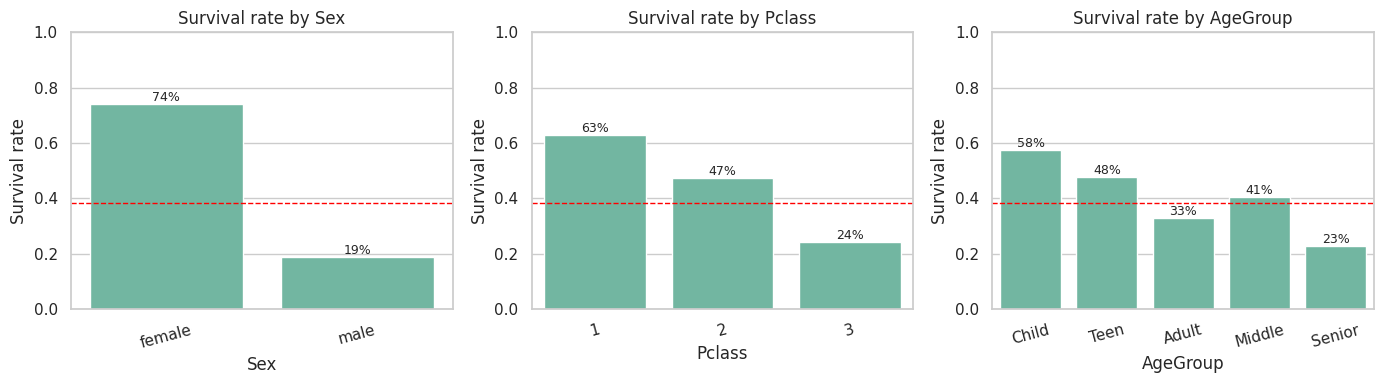

→ Gender is the dominant factor: 74% vs 19%. Class matters too: 63% (1st) vs 24% (3rd). Children (<12) survive at ~58% — the 'women and children first' effect is visible.


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "AgeGroup"]):
    sns.barplot(data=clean, x=col, y="Survived", ax=ax, errorbar=None)
    ax.set_title(f"Survival rate by {col}")
    ax.set_ylabel("Survival rate"); ax.set_ylim(0, 1)
    ax.axhline(clean.Survived.mean(), color="red", ls="--", lw=1)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.0%}",
                    (p.get_x()+p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

print("→ Gender is the dominant factor: 74% vs 19%. Class matters too: 63% (1st) vs 24% (3rd). "
      "Children (<12) survive at ~58% — the 'women and children first' effect is visible.")

## Sex × Class Heatmap

The two strongest factors interact. The heatmap shows survival rate per cell,
with `n=` under each cell so that small subgroups are not over-interpreted.

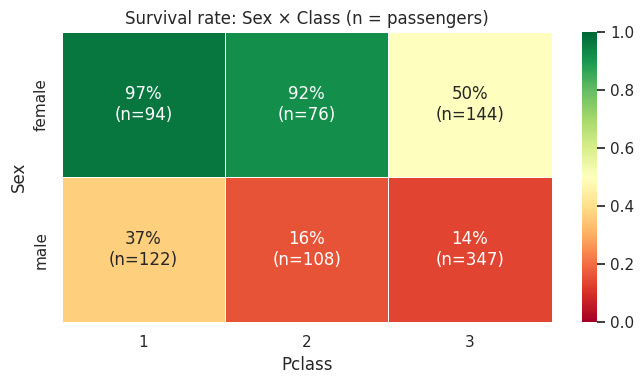

→ 1st/2nd-class women ~95%, 3rd-class women 50%. Men in any class ≤37%, and 3rd-class men only 14%. Class amplifies the gender gap dramatically.


In [6]:
pt  = clean.pivot_table(values="Survived", index="Sex", columns="Pclass", aggfunc="mean")
cnt = clean.pivot_table(values="Survived", index="Sex", columns="Pclass", aggfunc="count")
ann = pt.map(lambda v: f"{v:.0%}") + "\n(n=" + cnt.astype(int).astype(str) + ")"

plt.figure(figsize=(7, 4))
sns.heatmap(pt, annot=ann, fmt="", cmap="RdYlGn", vmin=0, vmax=1, linewidths=.5)
plt.title("Survival rate: Sex × Class (n = passengers)")
plt.tight_layout(); plt.show()

print("→ 1st/2nd-class women ~95%, 3rd-class women 50%. Men in any class ≤37%, "
      "and 3rd-class men only 14%. Class amplifies the gender gap dramatically.")

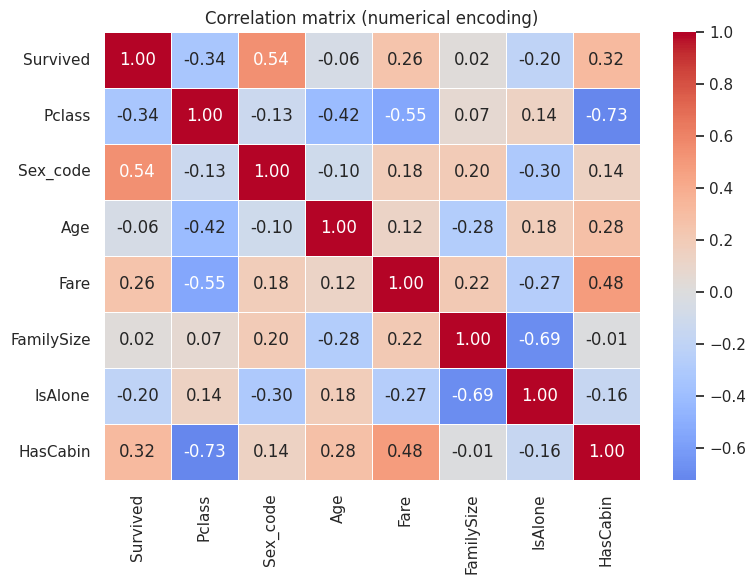

→ Sex (+0.54) and Pclass (-0.34) dominate. Fare and HasCabin are largely proxies for class. Age's weak linear correlation (-0.06) hides a strong non-linear pattern (children peak).


In [7]:
num = clean.assign(
    Sex_code      = (clean.Sex == "female").astype(int),
    Embarked_code = clean.Embarked.map({"S":0,"C":1,"Q":2}).astype(int),
)
cols = ["Survived","Pclass","Sex_code","Age","Fare","FamilySize","IsAlone","HasCabin"]
corr = num[cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5)
plt.title("Correlation matrix (numerical encoding)")
plt.tight_layout(); plt.show()

print("→ Sex (+0.54) and Pclass (-0.34) dominate. Fare and HasCabin are largely proxies for class. "
      "Age's weak linear correlation (-0.06) hides a strong non-linear pattern (children peak).")

## Findings

| Factor | Effect on survival | Strength |
|---|---|---|
| **Sex** | Women 74% vs men 19% | Strongest single factor |
| **Class** | 1st 63% → 3rd 24% | Very strong |
| **Age** | Children highest, elderly lowest | Moderate, non-linear |
| **Family size** | 2–4 best; solo and 5+ worst | Moderate |
| **HasCabin** | 3× higher (proxies class) | Moderate, confounded |
| **Embarked** | Cherbourg > Southampton | Weak, proxies class |

**Interpretation:** the "women and children first" evacuation was enforced strongly
in the aggregate, but class modulated the effect — 3rd-class women survived at
50% vs 95% for 1st/2nd-class women. This is the clearest signal in the data.

## Limitations & Next Steps

- **Training set only** (891 rows) — findings are sample-specific, not population-level.
- **Imputed ages** add noise, especially in small (Title, Class) subgroups.
- **Correlation ≠ causation** — sex, class, and cabin are entangled; the heatmap shows
  the descriptive pattern but doesn't isolate causes.
- **Non-monotone effects** (age) are missed by Pearson correlation and picked up only
  by grouping — a reminder to look at both.

Worth doing next: (1) train a baseline logistic regression on the engineered features,
(2) explicitly model a `Sex × Pclass` interaction given the EDA signal, (3) validate
findings on a held-out split — the EDA story should translate to a model that predicts
well without leaning on any single feature.